In [1]:
%matplotlib inline

from IPython.display import Markdown

from src.algorithm.FixedRoutePolicy import FixedRoutePolicy
from src.algorithm.NearestUnservedPolicy import NearestUnservedPolicy
from src.algorithm.MarginalCostFilterPolicy import MarginalCostFilterPolicy
from src.algorithm.SkipStopFixedRoutePolicy import SkipStopFixedRoutePolicy
from src.algorithm.ConstrainedInsertionPolicy import ConstrainedInsertionPolicy
from src.experiment import (
    compare_policies,
    plot_kpi_bars,
    plot_occupancy,
    plot_wait_distribution,
    run_trial,
    show_animations,
    summarize_comparison,
)
from src.map.PlanarMapProvider import PlanarMapProvider
from src.map.graph import PlanarStreetGraph

In [3]:
MAP_SEED = 42

graph = PlanarStreetGraph.generate(
    n_seeds=40,
    bounds=(0.0, 0.0, 5000.0, 5000.0),
    seed=MAP_SEED,
    stop_density=0.5,
)

provider = PlanarMapProvider(graph)
print(f"{len(provider.get_stops())} bus stops on this map")

73 bus stops on this map


In [5]:
N_TRIALS = 1000
BASE_SEED = 0

summary = summarize_comparison(
    policies=[
        ("Fixed route",      lambda g: FixedRoutePolicy(g)),
        ("Fixed route w/ skip", lambda g: SkipStopFixedRoutePolicy(g)),
        ("Nearest unserved", lambda g: NearestUnservedPolicy(g)),
        ("Marginal cost filter", lambda g: MarginalCostFilterPolicy(g)),
        ("Constrained insertion", lambda g: ConstrainedInsertionPolicy(g))
        
    ],
    graph=graph,
    n_trials=N_TRIALS,
    base_seed=BASE_SEED,
    # Forwarded to run_trial:
    max_requests=200,
    capacity=32,
    max_wait_s=7200.0
)
Markdown(summary.markdown)

Fixed route          :   0%|          | 0/1000 [00:00<?, ?it/s]

Fixed route w/ skip  :   0%|          | 0/1000 [00:00<?, ?it/s]

Nearest unserved     :   0%|          | 0/1000 [00:00<?, ?it/s]

Marginal cost filter :   0%|          | 0/1000 [00:00<?, ?it/s]

Constrained insertion:   0%|          | 0/1000 [00:00<?, ?it/s]

| Property | Fixed route | Fixed route w/ skip | Nearest unserved | Marginal cost filter | Constrained insertion |
| --- | --- | --- | --- | --- | --- |
| Fulfilled requests | 95.7 (±0.4%) | 109.1 (±0.5%) | 128.6 (±0.5%) | 128.8 (±0.5%) | 80.1 (±0.9%) |
| Cancelled requests | 104.3 (±0.3%) | 90.9 (±0.6%) | 71.4 (±0.8%) | 71.2 (±0.8%) | 119.9 (±0.6%) |
| Mean wait time | 3519.0 s (±0.4%) | 3678.2 s (±0.4%) | 2896.7 s (±0.5%) | 2891.9 s (±0.5%) | 3250.1 s (±0.5%) |
| P90 wait time | 6442.3 s (±0.2%) | 6487.3 s (±0.2%) | 6046.5 s (±0.3%) | 6033.0 s (±0.3%) | 6185.9 s (±0.3%) |
| Mean ride time | 5635.5 s (±0.4%) | 4410.6 s (±0.5%) | 3860.7 s (±0.6%) | 3863.7 s (±0.6%) | 1776.8 s (±1.3%) |
| Fulfillment rate | 47.9 % (±0.4%) | 54.5 % (±0.5%) | 64.3 % (±0.5%) | 64.4 % (±0.5%) | 40.0 % (±0.9%) |
| Served fraction | 47.9 % (±0.4%) | 54.5 % (±0.5%) | 64.3 % (±0.5%) | 64.4 % (±0.5%) | 40.0 % (±0.9%) |
| Throughput | 0.2 req/min (±0.4%) | 0.3 req/min (±0.5%) | 0.3 req/min (±0.5%) | 0.3 req/min (±0.5%) | 0.2 req/min (±0.9%) |
| Tick snapshots | 26264.8 (±0.2%) | 23062.2 (±0.2%) | 22788.6 (±0.2%) | 22818.3 (±0.2%) | 20031.8 (±0.2%) |
| Fulfilled (wait samples) | 95.7 (±0.4%) | 109.1 (±0.5%) | 128.6 (±0.5%) | 128.8 (±0.5%) | 80.1 (±0.9%) |
| Min wait time | 66.4 s (±6.1%) | 92.5 s (±5.9%) | 56.8 s (±6.0%) | 58.6 s (±6.0%) | 89.4 s (±6.2%) |
| Max wait time | 7125.4 s (±0.1%) | 7142.3 s (±0.0%) | 7114.0 s (±0.1%) | 7112.9 s (±0.1%) | 7078.5 s (±0.1%) |
| Min ride time | 93.5 s (±6.4%) | 72.9 s (±6.8%) | 20.6 s (±6.9%) | 20.2 s (±6.8%) | 30.1 s (±6.2%) |
| Max ride time | 10747.3 s (±0.1%) | 9321.6 s (±0.4%) | 18922.2 s (±0.6%) | 18953.9 s (±0.6%) | 11662.5 s (±1.6%) |

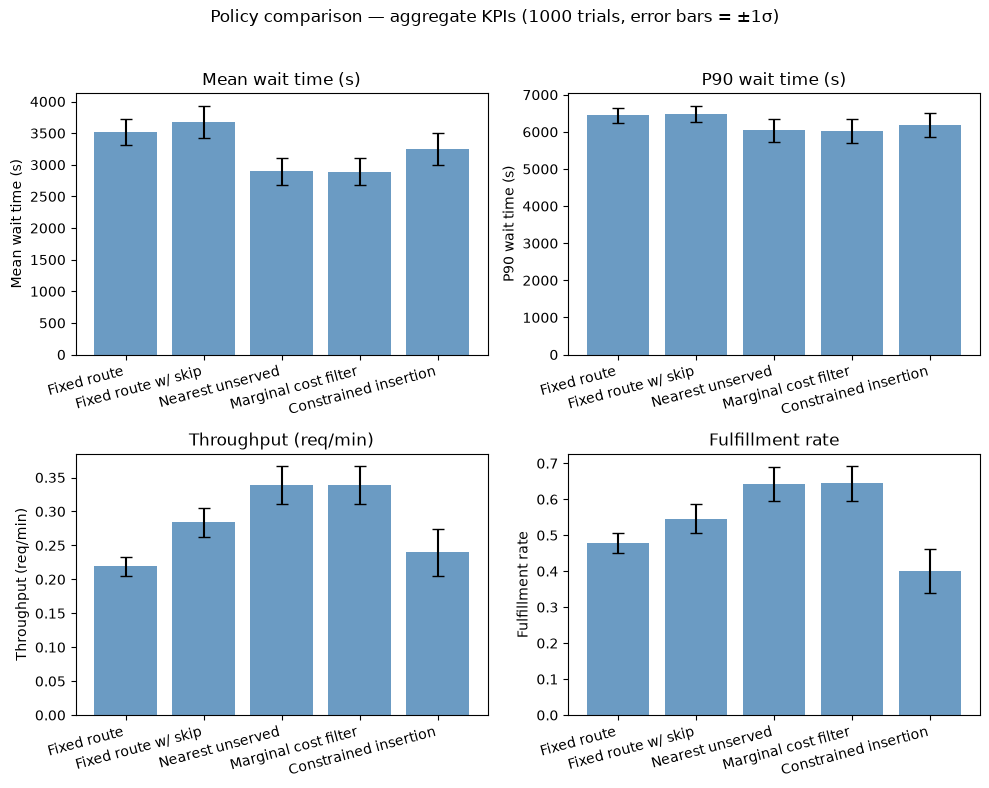

In [6]:
fig = plot_kpi_bars(
    summary.results,
    fields=["mean_wait_time", "p90_wait_time", "throughput", "fulfillment_rate"],
    title=f"Policy comparison — aggregate KPIs "
          f"({N_TRIALS} trials, error bars = ±1σ)",
)

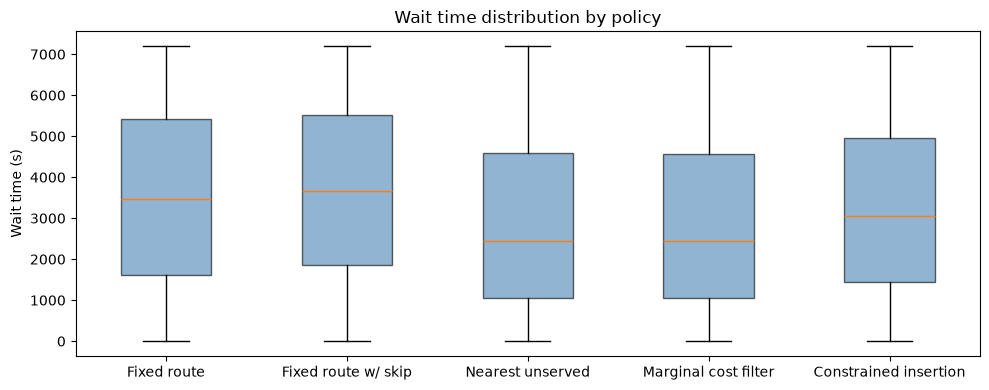

In [7]:
fig = plot_wait_distribution(summary.results)

In [7]:
# fig = plot_occupancy(summary.results)

In [9]:
MAP_SEED = 42

graph = PlanarStreetGraph.generate(
    n_seeds= 75,
    bounds=(0.0, 0.0, 5000.0, 5000.0),
    seed=MAP_SEED,
    stop_density=0.5,
)

provider = PlanarMapProvider(graph)
print(f"{len(provider.get_stops())} bus stops on this map")

152 bus stops on this map


In [10]:
N_TRIALS = 1000
BASE_SEED = 0

summary = summarize_comparison(
    policies=[
        ("Fixed route",      lambda g: FixedRoutePolicy(g)),
        ("Fixed route w/ skip", lambda g: SkipStopFixedRoutePolicy(g)),
        ("Nearest unserved", lambda g: NearestUnservedPolicy(g)),
        ("Marginal cost filter", lambda g: MarginalCostFilterPolicy(g)),
        ("Constrained insertion", lambda g: ConstrainedInsertionPolicy(g))
        
    ],
    graph=graph,
    n_trials=N_TRIALS,
    base_seed=BASE_SEED,
    # Forwarded to run_trial:
    max_requests=200,
    capacity=32,
    max_wait_s=7200.0
)
Markdown(summary.markdown)

Fixed route          :   0%|          | 0/1000 [00:00<?, ?it/s]

Fixed route w/ skip  :   0%|          | 0/1000 [00:00<?, ?it/s]

Nearest unserved     :   0%|          | 0/1000 [00:00<?, ?it/s]

Marginal cost filter :   0%|          | 0/1000 [00:00<?, ?it/s]

Constrained insertion:   0%|          | 0/1000 [00:00<?, ?it/s]

| Property | Fixed route | Fixed route w/ skip | Nearest unserved | Marginal cost filter | Constrained insertion |
| --- | --- | --- | --- | --- | --- |
| Fulfilled requests | 67.6 (±0.5%) | 96.5 (±0.4%) | 103.4 (±0.4%) | 103.8 (±0.4%) | 55.0 (±0.6%) |
| Cancelled requests | 132.4 (±0.2%) | 103.5 (±0.4%) | 96.6 (±0.5%) | 96.2 (±0.5%) | 145.0 (±0.2%) |
| Mean wait time | 3394.4 s (±0.5%) | 3582.4 s (±0.4%) | 2626.3 s (±0.5%) | 2633.9 s (±0.5%) | 3519.9 s (±0.5%) |
| P90 wait time | 6454.6 s (±0.2%) | 6443.0 s (±0.2%) | 5974.8 s (±0.4%) | 5979.4 s (±0.4%) | 6424.6 s (±0.3%) |
| Mean ride time | 7615.1 s (±0.5%) | 4909.2 s (±0.4%) | 4836.4 s (±0.6%) | 4824.8 s (±0.6%) | 953.7 s (±0.9%) |
| Fulfillment rate | 33.8 % (±0.5%) | 48.2 % (±0.4%) | 51.7 % (±0.4%) | 51.9 % (±0.4%) | 27.5 % (±0.6%) |
| Served fraction | 33.8 % (±0.5%) | 48.2 % (±0.4%) | 51.7 % (±0.4%) | 51.9 % (±0.4%) | 27.5 % (±0.6%) |
| Throughput | 0.1 req/min (±0.6%) | 0.3 req/min (±0.5%) | 0.3 req/min (±0.5%) | 0.3 req/min (±0.5%) | 0.2 req/min (±0.6%) |
| Tick snapshots | 31027.7 (±0.4%) | 23091.0 (±0.2%) | 22775.1 (±0.2%) | 22823.8 (±0.2%) | 19346.0 (±0.1%) |
| Fulfilled (wait samples) | 67.6 (±0.5%) | 96.5 (±0.4%) | 103.4 (±0.4%) | 103.8 (±0.4%) | 55.0 (±0.6%) |
| Min wait time | 77.6 s (±6.1%) | 135.5 s (±5.5%) | 102.5 s (±5.1%) | 102.0 s (±5.1%) | 175.3 s (±5.3%) |
| Max wait time | 7100.4 s (±0.1%) | 7128.4 s (±0.1%) | 7092.7 s (±0.1%) | 7096.1 s (±0.1%) | 7089.4 s (±0.1%) |
| Min ride time | 190.4 s (±6.3%) | 98.7 s (±5.5%) | 35.1 s (±5.3%) | 34.7 s (±5.3%) | 35.9 s (±5.3%) |
| Max ride time | 14778.0 s (±0.1%) | 10522.0 s (±0.4%) | 19512.4 s (±0.4%) | 19524.6 s (±0.4%) | 5345.8 s (±2.6%) |

In [11]:
# more requests
summary = summarize_comparison(
    policies=[
        ("Fixed route",      lambda g: FixedRoutePolicy(g)),
        ("Fixed route w/ skip", lambda g: SkipStopFixedRoutePolicy(g)),
        ("Nearest unserved", lambda g: NearestUnservedPolicy(g)),
        ("Marginal cost filter", lambda g: MarginalCostFilterPolicy(g)),
        ("Constrained insertion", lambda g: ConstrainedInsertionPolicy(g))
        
    ],
    graph=graph,
    n_trials=N_TRIALS,
    base_seed=BASE_SEED,
    # Forwarded to run_trial:
    max_requests=500,
    capacity=32,
    max_wait_s=7200.0
)
Markdown(summary.markdown)

Fixed route          :   0%|          | 0/1000 [00:00<?, ?it/s]

Fixed route w/ skip  :   0%|          | 0/1000 [00:00<?, ?it/s]

Nearest unserved     :   0%|          | 0/1000 [00:00<?, ?it/s]

Marginal cost filter :   0%|          | 0/1000 [00:00<?, ?it/s]

Constrained insertion:   0%|          | 0/1000 [00:00<?, ?it/s]

| Property | Fixed route | Fixed route w/ skip | Nearest unserved | Marginal cost filter | Constrained insertion |
| --- | --- | --- | --- | --- | --- |
| Fulfilled requests | 121.4 (±0.3%) | 176.2 (±0.4%) | 174.4 (±0.5%) | 174.9 (±0.5%) | 116.0 (±0.5%) |
| Cancelled requests | 341.8 (±0.1%) | 288.7 (±0.2%) | 286.8 (±0.3%) | 286.4 (±0.3%) | 368.5 (±0.2%) |
| Mean wait time | 3430.2 s (±0.3%) | 3556.6 s (±0.3%) | 2980.6 s (±0.3%) | 2982.3 s (±0.3%) | 3506.0 s (±0.3%) |
| P90 wait time | 6359.7 s (±0.2%) | 6414.6 s (±0.2%) | 6137.8 s (±0.2%) | 6137.3 s (±0.2%) | 6400.7 s (±0.2%) |
| Mean ride time | 7005.9 s (±0.3%) | 4913.5 s (±0.3%) | 3749.1 s (±0.8%) | 3742.8 s (±0.8%) | 1074.4 s (±0.7%) |
| Fulfillment rate | 26.2 % (±0.3%) | 37.9 % (±0.3%) | 37.8 % (±0.5%) | 37.9 % (±0.5%) | 23.9 % (±0.5%) |
| Served fraction | 24.3 % (±0.3%) | 35.2 % (±0.4%) | 34.9 % (±0.5%) | 35.0 % (±0.5%) | 23.2 % (±0.5%) |
| Throughput | 0.2 req/min (±0.3%) | 0.3 req/min (±0.4%) | 0.3 req/min (±0.5%) | 0.3 req/min (±0.5%) | 0.2 req/min (±0.5%) |
| Tick snapshots | 36000.0 (±0.0%) | 36000.0 (±0.0%) | 36000.0 (±0.0%) | 36000.0 (±0.0%) | 36000.0 (±0.0%) |
| Fulfilled (wait samples) | 121.4 (±0.3%) | 176.2 (±0.4%) | 174.4 (±0.5%) | 174.9 (±0.5%) | 116.0 (±0.5%) |
| Min wait time | 50.9 s (±6.3%) | 65.9 s (±5.9%) | 68.2 s (±5.7%) | 65.7 s (±5.7%) | 73.9 s (±6.1%) |
| Max wait time | 7133.2 s (±0.1%) | 7158.2 s (±0.0%) | 7140.7 s (±0.0%) | 7139.2 s (±0.1%) | 7138.8 s (±0.1%) |
| Min ride time | 89.0 s (±6.4%) | 52.2 s (±5.7%) | 19.2 s (±5.6%) | 19.1 s (±5.6%) | 19.0 s (±5.7%) |
| Max ride time | 14831.1 s (±0.1%) | 11195.4 s (±0.3%) | 25891.5 s (±1.0%) | 25974.6 s (±1.0%) | 8451.3 s (±2.8%) |